# Más allá: identidades de conciliación, ajustes como líneas y una comparación de regímenes sobre una misma cartera

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 01 a 07 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la afirmación BS-5 del SDD en sus cuatro partes y decir qué evidencia tiene cada parte y qué no afirma;
- correr la compuerta de conciliación en seis fechas de reporte, plantar defectos en las tablas y ver qué identidad nombra cada uno, y medir el tamaño del menor defecto que la compuerta detecta;
- mostrar que los ajustes son líneas separadas que cambian la cobertura total y nada más;
- reproducir el ejemplo de no linealidad, verificar la desigualdad ponderado sobre promedio como una propiedad en el régimen convexo, y encontrar dónde falla;
- verificar que los tres regímenes sobre un banco sintético concilian mediante un puente en cada escenario, y decir qué no es esa comparación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Doce archivos versionados, de dos casos.

- **C06**, las seis fechas de reporte `data/derived/C06/rd-2006-12.json`, `rd-2008-12.json`, `rd-2010-12.json`, `rd-2019-12.json`, `rd-2020-06.json` y `rd-2023-06.json` (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`): la conciliación del movimiento de la cobertura y del valor contable bruto (`outputs.reconciliation`), el waterfall, los totales por etapa y el bloque de no linealidad.
- **C07**, los seis escenarios `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` y `combined-severe.json`: Banco Andino, un banco **sintético** generado y calibrado a agregados públicos de la CMF. No es un banco real ni evidencia sobre ningún banco. La comparación de los tres regímenes, el puente, los ajustes y las filas de pruebas.

Todos los archivos los calculó un motor más antiguo que el instalado; el cuaderno imprime ambas versiones. **No se escribió ningún archivo para este cuaderno**: cada número de abajo se lee de estos archivos o lo calcula el motor sobre ellos, y los defectos plantados se hacen sobre copias en memoria.

In [2]:
# Cargar las seis fechas del C06 y los seis escenarios del C07 e imprimir las versiones del motor que los calcularon
from scipy.special import ndtri

from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "es"
ROOT = Path("../../..").resolve()
C06_DATES = ["2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06"]
C07_NAMES = ["base", "recession", "house-price-fall", "consumer-arrears-shock", "uf-inflation-spike", "combined-severe"]


def read(case, name):
    return json.loads((ROOT / "data" / "derived" / case / name).read_text(encoding="utf-8"))


c06 = {d: read("C06", f"rd-{d}.json") for d in C06_DATES}
c07 = {n: read("C07", f"{n}.json") for n in C07_NAMES}
print("C06 calculado por el motor:", sorted({a["provenance"]["riskvalidation_version"] for a in c06.values()}), "| C07:", sorted({a["provenance"]["riskvalidation_version"] for a in c07.values()}), "| motor instalado:", md.version("riskvalidation"))
print("C07 sintético en cada archivo:", si_no(all(a["outputs"]["synthetic"] and a["provenance"]["truth_status"] == "synthetic-calibrated" for a in c07.values())))
print("aviso del C07 (primer archivo):", c07["base"]["outputs"]["notice"][LANG])

C06 calculado por el motor: ['1.0.1'] | C07: ['1.0.1'] | motor instalado: 1.0.1
C07 sintético en cada archivo: sí
aviso del C07 (primer archivo): Datos sintéticos: Banco Andino es un banco generado, calibrado a agregados públicos del sistema de la CMF; no es un banco real ni evidencia sobre ningún banco. CMF B-1 es la provisión estatutaria que los bancos chilenos constituyen sobre colocaciones; la columna IFRS 9 es una medida de comparación, no la provisión que los bancos chilenos constituyen sobre colocaciones (CNCB A-2 N 5 deja las colocaciones a B-1); el Anejo 9 del BdE es la solución alternativa del PGC español. Montos en CLP.


## Método

La afirmación **BS-5** del SDD tiene cuatro partes. Cada una es un enunciado que puede fallar, y cada una se prueba abajo sobre archivos versionados con el motor.

1. **La conciliación de IFRS 7 cierra como una compuerta.** Doce identidades atan las tablas por etapa al waterfall, juzgadas por `check_identities` con la base de tolerancia $|\mathrm{diferencia}| \le \mathrm{tolerancia} \times \max(1, G)$, con $G$ la suma de los montos absolutos de cierre de las filas del valor contable bruto (cuaderno 04). Una compuerta vale por su poder de detección: el cuaderno planta defectos y mide el tamaño del menor que detecta.
2. **Los ajustes son líneas separadas.** La cobertura total es $\mathrm{CT} = \mathrm{PCE}_{\mathrm{modelo}} + \sum_k \mathrm{AJ}_k$ y los ajustes nunca entran a la PCE del modelo ni a la PCE de etapa (BCBS d350, párrafos 50 y 51; BCE 2024). La prueba es una invariancia: cambiar los ajustes cambia el total y deja intactas las cifras del modelo.
3. **La no linealidad de la PCE ponderada se reproduce.** Con la PD condicional de un factor $PD(z) = \Phi\bigl((\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z)/\sqrt{1-\rho}\bigr)$ (BCBS 2005; Gordy 2003), que es convexa donde $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, la desigualdad de Jensen da $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: la PD ponderada es al menos la PD en el factor medio ponderado **en el régimen convexo**, y puede quedar bajo ella fuera de él. La prueba es un barrido de propiedad con semilla a través de `nonlinearity_test` del motor, más el ejemplo de referencia y las filas versionadas.
4. **Un banco sintético se provisiona bajo tres regímenes con un puente de brecha.** CMF B-1, IFRS 9 como medida de comparación y Anejo 9 del Banco de España (cuaderno 06). La prueba es una conciliación: los totales son iguales a la suma de sus segmentos y el total B-1 más los pasos del puente es igual al total IFRS 9, en cada escenario.

Lo que la afirmación no es: no es una validación de ningún régimen ni de ningún banco, no declara cumplimiento, y la ausencia de una comparación pública de tres regímenes es lo que encontró la investigación (dossiers 02 y 03), NO VERIFICADO más allá de las búsquedas que esos dossiers registran.

## Estado del arte

Lo que la práctica y la investigación encontraron antes de este trabajo, con su fuente:

| Práctica | Qué enuncia | Fuente |
|---|---|---|
| Medición de IFRS 9 | objetivo y principios, no fórmulas: la norma «generalmente no prescribe métodos detallados particulares» | GPPC 2016, sección 2.1.1.1; IFRS 9 5.5.17 |
| Conciliación de la cobertura | una revelación por etapa de la cobertura de apertura a la de cierre y del valor contable bruto | IFRS 7 35H y 35I |
| No linealidad | se necesita más de un escenario cuando la pérdida no es lineal en la trayectoria macro; los ajustes solo de PIB la ignoran y subestiman el impacto medio | GPPC 2016, 2.8.1.2; BCE 2024; BCBS d350, párrafo 36(a) |
| Ajustes | deben apoyarse en una metodología, estar atribuidos, asignarse a nivel de parámetro y reflejarse en las etapas; cerca de una cuarta parte de la cobertura de la cartera vigente venía de ajustes en la muestra del BCE | BCE 2024; BCBS d350, párrafos 50 y 51 |
| Chile | los préstamos se provisionan bajo CMF B-1, no bajo el deterioro de IFRS 9 | CNCB A-2 N 5, B-1 |
| España | PCE tipo IFRS 9 con soluciones alternativas supervisoras | Circular 4/2017, Circular 6/2021 |
| Comparación de los regímenes | la investigación persistida (dossiers 02 y 03) **no encontró una comparación pública de los tres sobre una cartera** | las búsquedas de los propios dossiers, NO VERIFICADO más allá de ellas |

La práctica enuncia entonces las identidades como una revelación, los ajustes como un principio y los regímenes como textos separados. No corre las identidades como una compuerta con un umbral de detección medido, no muestra una invariancia de los ajustes y no pone los regímenes sobre una misma cartera.

## Más allá del estado del arte

Las cuatro partes de BS-5, cada una con su prueba. Los archivos de evidencia son los de la afirmación (`data/derived/C06/rd-2008-12.json`, `data/derived/C07/base.json`) y las otras fechas y escenarios que la extienden.

### Parte 1: las identidades cierran en seis fechas

Para cada fecha del C06 la celda reconstruye las filas por etapa con el motor, corre `check_identities` (que debe devolver una lista vacía), imprime el número de identidades, el mayor residuo, $G$ y el límite absoluto, y compara la luz de la prueba propia del motor `reconciliation_identities` con la fila versionada.

In [3]:
# Reconstruir las filas por etapa de cada fecha del C06 y correr la compuerta de identidades y la prueba propia del motor
def moves(row):
    return {m_["line_id"]: m_["amount"] for m_ in row["movements"]}


def rows_of(art):
    recon = art["outputs"]["reconciliation"]
    allowance = [rec.allowance_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["allowance"]]
    gca = [rec.gca_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["gross_carrying_amount"]]
    lines = [dict(line) for line in art["outputs"]["waterfall"]["lines"]]
    stage_ecl = {r["stage"]: r["ecl"] for r in art["outputs"]["stage_summary"]["rows"]}
    return allowance, gca, lines, stage_ecl


for d, art in c06.items():
    allowance, gca, lines, stage_ecl = rows_of(art)
    residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
    G = rec.gross_total(gca)
    test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="L1-dth")
    committed = [t for t in art["tests"] if t["test_id"] == "ifrs9.reconciliation_identities"][0]
    print(d, "| identidades:", len(residuals), "| fallan:", rec.check_identities(allowance, gca, lines, stage_ecl), "| mayor residuo:", f"{max(residuals.values()):.1e}", "| G (millones de USD):", round(G / 1e6, 1), "| límite, USD:", round(1e-6 * G, 1), "|", si_no(test.light.value), si_no(committed["light"]))

2006-12 | identidades: 12 | fallan: [] | mayor residuo: 1.5e-05 | G (millones de USD): 47124.4 | límite, USD: 47124.4 | verde verde
2008-12 | identidades: 12 | fallan: [] | mayor residuo: 1.2e-07 | G (millones de USD): 47247.6 | límite, USD: 47247.6 | verde verde
2010-12 | identidades: 12 | fallan: [] | mayor residuo: 3.8e-06 | G (millones de USD): 55459.9 | límite, USD: 55459.9 | verde verde
2019-12 | identidades: 12 | fallan: [] | mayor residuo: 1.5e-05 | G (millones de USD): 99603.2 | límite, USD: 99603.2 | verde verde
2020-06 | identidades: 12 | fallan: [] | mayor residuo: 1.3e-05 | G (millones de USD): 99710.5 | límite, USD: 99710.5 | verde verde
2023-06 | identidades: 12 | fallan: [] | mayor residuo: 1.2e-07 | G (millones de USD): 116761.4 | límite, USD: 116761.4 | verde verde


### Parte 2: una compuerta que detecta defectos plantados, y su umbral medido

Una compuerta que no puede fallar no prueba nada. La celda planta seis defectos de 1.000.000 USD sobre copias de las tablas de 2008, uno a la vez, y pregunta qué identidades fallan: un movimiento de la cobertura sin su cierre, un movimiento del valor contable bruto, el cierre del waterfall, una línea del waterfall, la PCE de etapa y un cierre de la cobertura. Una segunda celda mide luego el umbral de detección: biseca el tamaño del primer defecto entre 0 y 100 millones y encuentra el tamaño en que la compuerta empieza a fallar, que debería ser el límite de la tolerancia $10^{-6} \times G$.

In [4]:
# Plantar seis defectos de un millón de USD, uno a la vez, sobre copias de las tablas de 2008
art = c06["2008-12"]
allowance, gca, lines, stage_ecl = rows_of(art)
recon = art["outputs"]["reconciliation"]
D = 1_000_000.0


def bump_allowance(stage_index, line_id, amount, closing_too=False):
    r = recon["allowance"][stage_index]
    new = rec.allowance_rollforward(r["stage"], r["opening"], {**moves(r), line_id: moves(r)[line_id] + (0.0 if closing_too else amount)}, r["closing"] + (amount if closing_too else 0.0))
    return allowance[:stage_index] + [new] + allowance[stage_index + 1:]


def bump_gca(stage_index, line_id, amount):
    r = recon["gross_carrying_amount"][stage_index]
    new = rec.gca_rollforward(r["stage"], r["opening"], {**moves(r), line_id: moves(r)[line_id] + amount}, r["closing"])
    return gca[:stage_index] + [new] + gca[stage_index + 1:]


def bump_line(line_id, amount):
    return [dict(line, amount=line["amount"] + amount) if line["id"] == line_id else dict(line) for line in lines]


cases = {
    "movimiento de la cobertura, Etapa 1, cierre sin cambio": (bump_allowance(0, "remeasurement", D), gca, lines, stage_ecl),
    "movimiento del valor bruto, Etapa 2": (allowance, bump_gca(1, "repayments", D), lines, stage_ecl),
    "línea de cierre del waterfall": (allowance, gca, bump_line("closing", D), stage_ecl),
    "línea de remedición del waterfall": (allowance, gca, bump_line("remeasurement", D), stage_ecl),
    "PCE de etapa, Etapa 1": (allowance, gca, lines, {**stage_ecl, "stage1": stage_ecl["stage1"] + D}),
    "cierre de la cobertura, Etapa 2": (bump_allowance(1, "remeasurement", D, closing_too=True), gca, lines, stage_ecl),
}
print("tablas intactas, fallan:", rec.check_identities(allowance, gca, lines, stage_ecl))
for label, args in cases.items():
    failing = rec.check_identities(*args)
    print(f"{label:62s} detectado: {si_no(bool(failing))} | {failing}")

tablas intactas, fallan: []
movimiento de la cobertura, Etapa 1, cierre sin cambio         detectado: sí | ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']
movimiento del valor bruto, Etapa 2                            detectado: sí | ['gca-rollforward:stage2']
línea de cierre del waterfall                                  detectado: sí | ['waterfall-closes', 'waterfall-equals-stage-closings']
línea de remedición del waterfall                              detectado: sí | ['waterfall-closes', 'waterfall-lines-equal-movements']
PCE de etapa, Etapa 1                                          detectado: sí | ['stage-closing-equals-ecl:stage1']
cierre de la cobertura, Etapa 2                                detectado: sí | ['allowance-rollforward:stage2', 'waterfall-equals-stage-closings', 'stage-closing-equals-ecl:stage2']


El umbral de detección. Para un defecto del primer tipo, la celda pregunta a `check_identities` si se detecta, biseca el tamaño entre 0 y 100 millones de USD durante 80 pasos, y compara el tamaño donde la respuesta cambia con $10^{-6} \times G$. Luego lista nueve tamaños de 1 a 100 millones de USD, y repite tres de ellos con una tolerancia de $10^{-9}$.

In [5]:
# Medir el umbral de detección de la compuerta por bisección sobre el tamaño de un defecto
def caught(size):
    return bool(rec.check_identities(bump_allowance(0, "remeasurement", size), gca, lines, stage_ecl))


G = rec.gross_total(gca)
low, high = 0.0, 1e8
for _ in range(80):
    middle = 0.5 * (low + high)
    low, high = (low, middle) if caught(middle) else (middle, high)
print("límite de la tolerancia 1e-6 x G, USD:", round(1e-6 * G, 3))
print("mayor tamaño no detectado, menor tamaño detectado, USD:", round(low, 3), round(high, 3))
print("el umbral es igual al límite con tolerancia de 1 USD:", si_no(abs(high - 1e-6 * G) < 1.0))
sizes = [10.0 ** k for k in range(0, 9)]
detected = [caught(s) for s in sizes]
for s, c in zip(sizes, detected):
    print("defecto, USD", f"{s:12.0f}", "detectado:", si_no(c))
print("detección con tolerancia 1e-9 (límite en USD):", round(1e-9 * G, 2), [si_no(bool(rec.check_identities(bump_allowance(0, "remeasurement", s), gca, lines, stage_ecl, tolerance=1e-9))) for s in (10.0, 100.0, 1000.0)])

límite de la tolerancia 1e-6 x G, USD: 47247.616
mayor tamaño no detectado, menor tamaño detectado, USD: 47247.616 47247.616
el umbral es igual al límite con tolerancia de 1 USD: sí
defecto, USD            1 detectado: no
defecto, USD           10 detectado: no
defecto, USD          100 detectado: no
defecto, USD         1000 detectado: no
defecto, USD        10000 detectado: no
defecto, USD       100000 detectado: sí
defecto, USD      1000000 detectado: sí
defecto, USD     10000000 detectado: sí
defecto, USD    100000000 detectado: sí
detección con tolerancia 1e-9 (límite en USD): 47.25 ['no', 'sí', 'sí']


### Parte 3: los ajustes son líneas, y solo se mueve el total

La celda reconstruye los dos ajustes de Banco Andino como en el cuaderno 04 y los pasa a `portfolio_allowance` del motor con una cuenta construida por etapa que representa la PCE de etapa versionada, de modo que las cifras del modelo son las del archivo. Luego multiplica los ajustes por 0, 1 y 10 y verifica la invariancia: la PCE del modelo y la PCE por etapa nunca cambian, el total de ajustes y la cobertura total cambian exactamente en los montos de los ajustes. Una última verificación lleva un ajuste en un cierre de Etapa 1 del C06 y pregunta a `check_identities` si el cierre de la etapa sigue siendo igual a la PCE de etapa más el ajuste que se lleva allí: falla cuando el ajuste no está en el cierre y cierra cuando está.

In [6]:
# Escalar los ajustes y verificar que solo se mueven el total de ajustes y la cobertura total
detail = c07["base"]["outputs"]["ifrs9_detail"]
split = {amount: target for target, amount in [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]["extras"]["by_target"].items() if amount}
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert", target=split[o["amount"]], segment_id=o["segment_id"],
                stage=o["stage"], amount=o["amount"], staging_effect="none", review_date="2026-08-31", currency="CLP")  # fecha de revisión: un insumo de la lección
    for o in detail["overlays"]
]
by_stage = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
stage_codes = np.array([1, 2, 3])
ecl12 = np.array([by_stage["stage1"], 0.0, 0.0])
ecl_life = np.array([0.0, by_stage["stage2"], 0.0])
ecl_s3 = np.array([0.0, 0.0, by_stage["stage3"]])
baseline = ecl_engine.portfolio_allowance(stage_codes, ecl12, ecl_life, ecl_s3, overlays=overlays)
for factor in (0, 1, 10):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    result = ecl_engine.portfolio_allowance(stage_codes, ecl12, ecl_life, ecl_s3, overlays=scaled)
    print("ajustes x", factor, "| total del modelo igual:", si_no(result.model_total == baseline.model_total), "| por etapa igual:", si_no(result.by_stage == baseline.by_stage), "| total de ajustes, millones de CLP:", round(result.overlay_total / 1e6, 1), "| el total se mueve exactamente en los ajustes:", si_no(abs(result.total - (result.model_total + result.overlay_total)) < 1e-6))
print("cobertura total y provisión IFRS 9 versionada, millones de CLP:", round(baseline.total / 1e6, 1), round(c07["base"]["impact"]["provision_ifrs9"]["value"] / 1e6, 1))
print("líneas de ajuste, nunca fusionadas:", [(l["id"], l["stage"]) for l in ovl.overlay_lines(overlays)])

allowance, gca, lines, stage_ecl = rows_of(c06["2008-12"])
OVERLAY = ovl.Overlay(id="LESSON", rationale_en="lesson", rationale_es="lección", method="expert", target="pd", segment_id=None, stage=None, amount=10_000_000.0, staging_effect="none", review_date="2026-08-31", currency="USD")
not_carried = rec.check_identities(allowance, gca, lines, stage_ecl, overlays=[OVERLAY])
r1 = recon["allowance"][0]
carried_row = rec.allowance_rollforward("stage1", r1["opening"], {**moves(r1), "overlay-LESSON": OVERLAY.amount}, r1["closing"] + OVERLAY.amount)
carried_lines = [dict(l, amount=l["amount"] + OVERLAY.amount) if l["id"] == "closing" else dict(l) for l in lines] + [{"id": "overlay-LESSON", "kind": "overlay", "overlay_id": "LESSON", "amount": OVERLAY.amount, "stage": None}]
carried = rec.check_identities([carried_row] + allowance[1:], gca, carried_lines, stage_ecl, overlays=[OVERLAY])
print("un ajuste de 10 millones no llevado en el cierre: fallan:", not_carried)
print("el mismo ajuste llevado en el cierre de la Etapa 1 y como línea del waterfall: fallan:", carried)

ajustes x 0 | total del modelo igual: sí | por etapa igual: sí | total de ajustes, millones de CLP: 0.0 | el total se mueve exactamente en los ajustes: sí
ajustes x 1 | total del modelo igual: sí | por etapa igual: sí | total de ajustes, millones de CLP: 324.1 | el total se mueve exactamente en los ajustes: sí
ajustes x 10 | total del modelo igual: sí | por etapa igual: sí | total de ajustes, millones de CLP: 3241.3 | el total se mueve exactamente en los ajustes: sí
cobertura total y provisión IFRS 9 versionada, millones de CLP: 97592.0 97592.0
líneas de ajuste, nunca fusionadas: [('overlay-OVL-CARDS', 'stage1'), ('overlay-OVL-HOUSING', 'stage2')]
un ajuste de 10 millones no llevado en el cierre: fallan: ['stage-closing-equals-ecl:stage1']
el mismo ajuste llevado en el cierre de la Etapa 1 y como línea del waterfall: fallan: []


### Parte 4: la no linealidad, reproducida y acotada

Tres pruebas. Primero, el ejemplo de referencia (los insumos de la lección del cuaderno 03: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0{,}12$, $z = (+1, 0, -2)$, ponderaciones $(0{,}25; 0{,}5; 0{,}25)$) a través de `nonlinearity_test`. Segundo, las filas versionadas: el índice a nivel de PD de los seis segmentos del C07 recalculado desde su PD ponderada y su PD en el factor medio, y el índice a nivel de PCE de las seis fechas del C06 recalculado desde la PCE ponderada y la PCE en la trayectoria media. Tercero, un barrido con semilla de 4.000 sorteos aleatorios de $(PD^{\mathrm{TTC}}, \rho, z, w)$ a través de la prueba del motor, separado según si todos los factores de escenario están en la región convexa $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$. En la región convexa el índice no puede ser negativo (Jensen); fuera de ella, sí.

In [7]:
# El ejemplo de referencia y los índices versionados a nivel de PD y de PCE
example = ifrs9.nonlinearity_test(0.02, 0.12, np.array([1.0, 0.0, -2.0]), np.array([0.25, 0.5, 0.25]), model_id="lesson")
print("ejemplo de referencia: PD ponderada y PD en el factor medio (porcentaje), índice:", round(100 * example.extras["pd_weighted"], 3), round(100 * example.extras["pd_at_mean_z"], 3), round(example.metric, 4), "|", si_no(example.light.value))

segments = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.nonlinearity"]
indexes = [ecl_engine.non_linearity_index(t["extras"]["pd_weighted"], t["extras"]["pd_at_mean_z"]) for t in segments]
print("segmentos del C07: el índice a nivel de PD recalculado es igual al versionado:", si_no(all(abs(i - t["metric"]) < 1e-6 for i, t in zip(indexes, segments))), "| menor y mayor:", round(min(indexes), 3), round(max(indexes), 3))
for d, art in c06.items():
    block = art["outputs"]["non_linearity"]
    index = ecl_engine.non_linearity_index(block["ecl_weighted"], block["ecl_at_mean_path"])
    print(d, "| índice a nivel de PCE:", round(index, 5), "| igual al versionado:", si_no(abs(index - block["index"]) < 1e-9), "| ponderada al menos la PCE de la trayectoria media:", si_no(index >= 0.0))

ejemplo de referencia: PD ponderada y PD en el factor medio (porcentaje), índice: 2.681 1.8 0.4898 | verde
segmentos del C07: el índice a nivel de PD recalculado es igual al versionado: sí | menor y mayor: 0.156 0.956
2006-12 | índice a nivel de PCE: 0.00211 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: sí
2008-12 | índice a nivel de PCE: 0.02121 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: sí
2010-12 | índice a nivel de PCE: -0.00071 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: no
2019-12 | índice a nivel de PCE: 0.0232 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: sí
2020-06 | índice a nivel de PCE: 0.01279 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: sí
2023-06 | índice a nivel de PCE: 0.00622 | igual al versionado: sí | ponderada al menos la PCE de la trayectoria media: sí


El barrido. La celda sortea 4.000 casos con una semilla fija: una PD entre 0,1 % y 20 % (log-uniforme), una correlación entre 0,01 y 0,30, de dos a cinco escenarios con factores alrededor de un centro aleatorio entre $-5$ y $+1$, y ponderaciones de una distribución de Dirichlet. Cada uno pasa por `nonlinearity_test`. Cuenta los sorteos cuyos factores están todos en la región convexa, los índices negativos en cada grupo y las luces rojas, y termina con un ejemplo cóncavo explícito.

In [8]:
# Un barrido con semilla de sorteos aleatorios a través de la prueba del motor, separado por la región convexa
rng = np.random.default_rng(20261021)
draws = []
for _ in range(4000):
    pd_ttc = float(np.exp(rng.uniform(np.log(0.001), np.log(0.2))))
    rho = float(rng.uniform(0.01, 0.30))
    k = int(rng.integers(2, 6))
    z = rng.normal(rng.uniform(-5.0, 1.0), rng.uniform(0.3, 1.5), k)
    w = rng.dirichlet(np.ones(k))
    result = ifrs9.nonlinearity_test(pd_ttc, rho, z, w)
    convex = bool(np.all(z >= ndtri(pd_ttc) / math.sqrt(rho)))
    draws.append((convex, result.metric, float(np.sum(w * z)), result.light.value, result.extras["gauss_hermite_error"]))
convex_draws = [d for d in draws if d[0]]
other_draws = [d for d in draws if not d[0]]
print("sorteos:", len(draws), "| todos los factores en la región convexa:", len(convex_draws), "| otros:", len(other_draws))
print("región convexa: menor índice (nunca negativo):", round(min(d[1] for d in convex_draws), 6), "| negativos:", sum(d[1] < 0 for d in convex_draws))
print("fuera de ella: menor índice:", round(min(d[1] for d in other_draws), 4), "| negativos:", sum(d[1] < 0 for d in other_draws), "| luces rojas:", sum(d[3] == "red" for d in other_draws))
print("error de Gauss-Hermite a lo más 1e-9 en cada sorteo:", si_no(all(d[4] <= 1e-9 for d in draws)))
concave = ifrs9.nonlinearity_test(0.2, 0.3, np.array([-3.0, -4.0]), np.array([0.5, 0.5]), model_id="lesson")
print("un ejemplo cóncavo (PD, rho, z): índice y luz:", (0.2, 0.3, (-3.0, -4.0)), round(concave.metric, 5), si_no(concave.light.value), "| convexa desde z:", round(float(ndtri(0.2) / math.sqrt(0.3)), 3))

sorteos: 4000 | todos los factores en la región convexa: 3402 | otros: 598
región convexa: menor índice (nunca negativo): 0.0 | negativos: 0
fuera de ella: menor índice: -0.12 | negativos: 356 | luces rojas: 356
error de Gauss-Hermite a lo más 1e-9 en cada sorteo: sí
un ejemplo cóncavo (PD, rho, z): índice y luz: (0.2, 0.3, (-3.0, -4.0)) -0.01319 rojo | convexa desde z: -1.537


### Parte 5: tres regímenes, un banco sintético, un puente en cada escenario

La última prueba es una conciliación sobre los seis escenarios de Banco Andino. Para cada archivo la celda verifica que el total de cada régimen es igual a la suma de sus segmentos más las líneas sin asignar, que el total comparable B-1 más las provisiones adicionales es igual al total B-1 contabilizado, y que el total B-1 más los pasos del puente es igual al total IFRS 9. Verifica también que el archivo lleva el aviso de sintético en ambos idiomas. Imprime la razón de IFRS 9 a B-1: un enunciado sobre la misma cartera bajo reglas distintas, no sobre qué regla es la correcta.

In [9]:
# Conciliar los totales, el total B-1 contabilizado y el puente en cada uno de los seis escenarios
keys = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
checks = {"sums": [], "booked": [], "bridge": [], "notice": []}
for name, art in c07.items():
    out = art["outputs"]
    totals = {k: sum(r[k] for r in out["comparison"]["rows"]) + out["comparison"]["unallocated"][k] for k in keys}
    regimes = {r["regime"]: r["total_provision"] for r in out["regimes"]}
    checks["sums"].append(abs(totals["cmf_b1_provision"] - regimes["cmf-b1"]) < 1.0 and abs(totals["ifrs9_provision"] - regimes["ifrs9"]) < 1.0 and abs(totals["bde_annex9_provision"] - regimes["bde-annex9"]) < 1.0)
    checks["booked"].append(abs(out["b1_detail"]["booked_total"] - (regimes["cmf-b1"] + out["b1_detail"]["additional_provisions"]["amount"])) < 1.0)
    bridge_end = totals["cmf_b1_provision"] + sum(s["amount"] for s in out["gap_bridge"]["steps"])
    checks["bridge"].append(abs(bridge_end - totals["ifrs9_provision"]) < 1.0)
    checks["notice"].append(bool(out["notice"]["en"]) and bool(out["notice"]["es"]) and out["synthetic"])
    print(f"{name:24s} B-1: {regimes['cmf-b1'] / 1e9:8.1f} | IFRS 9: {regimes['ifrs9'] / 1e9:8.1f} | Anejo 9: {regimes['bde-annex9'] / 1e9:8.1f} | IFRS 9 / B-1: {regimes['ifrs9'] / regimes['cmf-b1']:6.3f} | residuo del puente, CLP: {abs(bridge_end - totals['ifrs9_provision']):.2f}")
print(si_no({k: all(v) for k, v in checks.items()}), "| escenarios:", len(c07))

base                     B-1:    152.0 | IFRS 9:     97.6 | Anejo 9:     79.6 | IFRS 9 / B-1:  0.642 | residuo del puente, CLP: 0.00
recession                B-1:    197.5 | IFRS 9:    169.8 | Anejo 9:    116.3 | IFRS 9 / B-1:  0.860 | residuo del puente, CLP: 0.00
house-price-fall         B-1:    168.9 | IFRS 9:    128.8 | Anejo 9:     94.6 | IFRS 9 / B-1:  0.763 | residuo del puente, CLP: 0.00
consumer-arrears-shock   B-1:    178.6 | IFRS 9:    126.3 | Anejo 9:     97.3 | IFRS 9 / B-1:  0.707 | residuo del puente, CLP: 0.00
uf-inflation-spike       B-1:    166.9 | IFRS 9:    117.4 | Anejo 9:     85.6 | IFRS 9 / B-1:  0.703 | residuo del puente, CLP: 0.00
combined-severe          B-1:    275.8 | IFRS 9:    327.8 | Anejo 9:    191.6 | IFRS 9 / B-1:  1.189 | residuo del puente, CLP: 0.00
{'sums': 'sí', 'booked': 'sí', 'bridge': 'sí', 'notice': 'sí'} | escenarios: 6


### Las pruebas, dibujadas

El panel izquierdo dibuja la detección de la compuerta ante un defecto de tamaño creciente en las tablas de 2008, en ejes logarítmicos: la recta vertical es el límite de la tolerancia $10^{-6} \times G$ y los escalones muestran qué tamaños detecta la compuerta. El panel derecho dibuja el barrido del índice de no linealidad contra el factor medio ponderado, en la región convexa (azul) y fuera de ella (rojo): los puntos azules nunca bajan de cero, los rojos pueden.

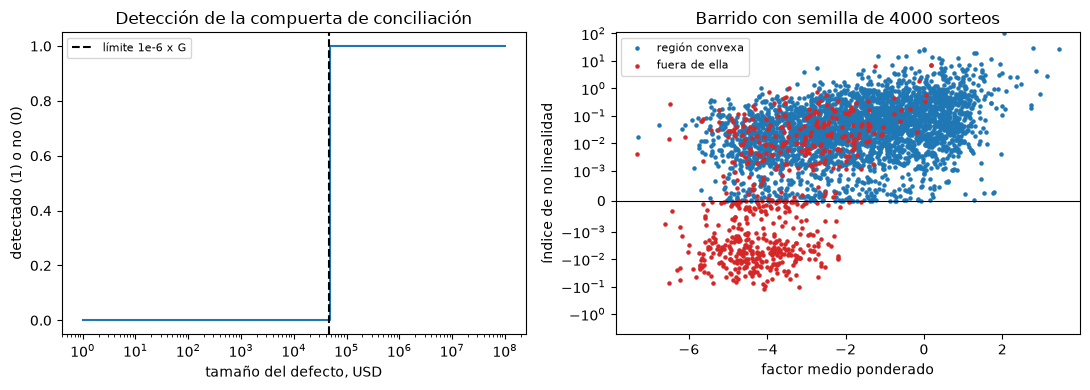

In [10]:
# Dibujar la detección de la compuerta por tamaño de defecto y el barrido de no linealidad por región
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
grid = np.logspace(0, 8, 160)
left.step(grid, [1.0 if caught(s) else 0.0 for s in grid], where="post", color="tab:blue")
left.axvline(1e-6 * G, color="black", linestyle="--", label="límite 1e-6 x G")
left.set_xscale("log")
left.set_xlabel("tamaño del defecto, USD")
left.set_ylabel("detectado (1) o no (0)")
left.set_title("Detección de la compuerta de conciliación")
left.legend(fontsize=8)

right.scatter([d[2] for d in convex_draws], [d[1] for d in convex_draws], s=5, color="tab:blue", label="región convexa")
right.scatter([d[2] for d in other_draws], [d[1] for d in other_draws], s=5, color="tab:red", label="fuera de ella")
right.axhline(0.0, color="black", linewidth=0.8)
right.set_yscale("symlog", linthresh=1e-3)
right.set_xlabel("factor medio ponderado")
right.set_ylabel("índice de no linealidad")
right.set_title("Barrido con semilla de 4000 sorteos")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Las identidades cierran en seis fechas.** En cada fecha del C06 las doce identidades se cumplen y `check_identities` devuelve una lista vacía. El mayor residuo es 1,5e-05 USD (2006-12, 2019-12), 1,3e-05 (2020-06), 3,8e-06 (2010-12) y 1,2e-07 (2008-12 y 2023-06), frente a límites absolutos de 47.124,4, 47.247,6, 55.459,9, 99.603,2, 99.710,5 y 116.761,4 USD (una millonésima de $G$, que va de 47,1 a 116,8 miles de millones de USD). La prueba propia del motor es verde en las seis fechas, como las filas versionadas. Los residuos son redondeo de los números guardados, al menos nueve órdenes de magnitud bajo el límite.
- **La compuerta detecta lo que debe, y su umbral es la tolerancia.** Seis defectos de 1.000.000 USD se detectan, cada uno por la identidad que lo nombra: un movimiento de la cobertura sin su cierre lo detectan `allowance-rollforward:stage1` y `waterfall-lines-equal-movements`, un movimiento del monto bruto `gca-rollforward:stage2`, el cierre del waterfall `waterfall-closes` y `waterfall-equals-stage-closings`, una línea del waterfall `waterfall-closes` y `waterfall-lines-equal-movements`, la PCE de etapa `stage-closing-equals-ecl:stage1` y un cierre de la cobertura tres identidades. La bisección encuentra que los defectos hasta 47.247,6 USD pasan y los mayores fallan: el umbral es igual a $10^{-6} \times G$ con tolerancia de 1 USD. Los tamaños de 1 a 10.000 USD pasan, desde 100.000 USD fallan, y con una tolerancia de $10^{-9}$ el límite es 47,25 USD y 100 USD se detecta.
- **Los ajustes cambian el total y nada más.** Con los ajustes multiplicados por 0, 1 y 10 el total del modelo y la PCE por etapa quedan iguales; el total de ajustes es 0, 324,1 y 3.241,3 millones de CLP y la cobertura total se mueve exactamente eso. En los montos versionados la cobertura total es 97.592,0 millones, igual a la provisión IFRS 9 versionada, y los ajustes siguen siendo dos líneas (`overlay-OVL-CARDS` en la Etapa 1, `overlay-OVL-HOUSING` en la Etapa 2). Un ajuste de 10 millones que no se lleva en el cierre de la Etapa 1 hace fallar `stage-closing-equals-ecl:stage1`, y llevarlo en el cierre y como línea del waterfall cierra todas las identidades: las identidades atan el ajuste a su etapa.
- **El ejemplo de no linealidad se reproduce.** La PD ponderada es 2,681 % y la PD en el factor medio 1,800 %, un índice de 0,4898. En los segmentos versionados del C07 el índice a nivel de PD recalculado desde las PD guardadas es igual al versionado y va de 0,156 a 0,956.
- **La PCE ponderada no siempre está sobre la PCE de la trayectoria media, y la afirmación dice dónde se cumple.** En las fechas versionadas del C06 el índice a nivel de PCE es 0,00211, 0,02121, $-0{,}00071$, 0,0232, 0,01279 y 0,00622: cinco de seis están en cero o sobre él y 2010-12 está bajo, lo que el motor lee como ámbar. El barrido de 4.000 sorteos con semilla a través de `nonlinearity_test` muestra por qué el enunciado necesita su calificativo: de 3.402 sorteos con todos los factores de escenario en la región convexa el menor índice es 0,0 y ninguno es negativo; de 598 sorteos con algún factor fuera de ella 356 son negativos (hasta $-0{,}12$) y todos ellos son rojos. Un ejemplo cóncavo (PD 0,2, $\rho = 0{,}3$, $z = -3$ y $-4$) da $-0{,}01319$, rojo, y la región convexa empieza en $z = -1{,}537$. El error de Gauss-Hermite es a lo más 1e-9 en cada sorteo.
- **Tres regímenes concilian en cada escenario.** En los seis archivos de Banco Andino los totales son iguales a la suma de sus segmentos más las líneas sin asignar, el total B-1 contabilizado es igual al total comparable más las provisiones adicionales, el puente de B-1 a IFRS 9 cierra con un residuo de 0,00 CLP, y cada archivo lleva el aviso de sintético en ambos idiomas. IFRS 9 sobre B-1 va de 0,642 en el base a 1,189 en el caso severo combinado.

Lo que BS-5 afirma, tal como lo sostiene la evidencia: la conciliación cierra como una compuerta cuyo umbral medido es una millonésima del valor contable bruto (no una millonésima de unidad de dinero); los ajustes son líneas separadas; la PD ponderada es al menos la PD en el factor medio en el régimen convexo, con el ejemplo reproducido; un banco sintético se provisiona bajo tres regímenes con un puente que concilia. Lo que no afirma: que algún régimen sea correcto, que la desigualdad a nivel de PCE versionada se cumpla en todas las fechas (no se cumple en 2010-12), que Banco Andino se parezca a un banco real, ni que no exista una comparación pública de los tres regímenes más allá de lo que encontró la investigación.

## Resumen

- BS-5 tiene cuatro partes, y cada una es una prueba sobre archivos versionados con el motor: la compuerta de conciliación, la invariancia de los ajustes, la no linealidad y la conciliación de tres regímenes.
- La compuerta cierra en seis fechas, detecta seis defectos plantados por nombre, y su umbral de detección medido es $10^{-6} \times G$, decenas de miles de USD en estas carteras.
- Los ajustes son líneas: cambiarlos mueve la cobertura total exactamente en su monto y no mueve nada más; las identidades atan cada uno a su etapa.
- La PD ponderada es al menos la PD en el factor medio en el régimen convexo y puede quedar bajo ella fuera de él; el índice a nivel de PCE versionado estuvo bajo cero una vez en seis fechas.
- Un banco sintético bajo CMF B-1, IFRS 9 y Anejo 9 concilia mediante un puente en seis escenarios, y el orden de los regímenes cambia con el escenario.
- La afirmación está acotada por su evidencia: ningún régimen se valida, el banco es sintético y la ausencia de una comparación pública es lo que encontró la investigación.

**Qué probar a continuación.** Planta un defecto de tu propio tamaño en la fila de la Etapa 3 y biseca su umbral; escala los ajustes por un factor negativo y lee qué dice `check_identities`; cambia la semilla del barrido. El texto de la afirmación y su evidencia están en la sección `## Beyond the state of the art` del SDD.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, sección 4.2: el modelo de un factor. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Capítulos A-2 (N 5) y B-1 (N 2, N 3, N 4 y N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 6/2021 de 22 de diciembre (BOE-A-2021-21666): las tablas de los puntos 140, 144 y 172, aplicables desde el 30 de junio de 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666